# Small Cap Fund Analysis

Run `small_cap_cleaning.ipynb` first. This notebook loads the fund-level metrics and creates the same comparison charts as the large-cap fund analysis.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [13]:
file_path = Path("Small_cap/analysis/small_cap_fund_results.csv")
small_cap_results = pd.read_csv(file_path)
small_cap_results["Start Date"] = pd.to_datetime(small_cap_results["Start Date"])
small_cap_results["End Date"] = pd.to_datetime(small_cap_results["End Date"])
charts_dir = Path("Small_cap/analysis/charts")
charts_dir.mkdir(parents=True, exist_ok=True)
display(small_cap_results.head())


,Fund,Start Date,End Date,Observations,Start NAV,End NAV,CAGR,Volatility,Maximum Drawdown,Sharpe Ratio
0,Nippon India Small Cap,2022-01-03,2025-12-31,980,96.4493,187.0214,0.180446,0.162468,-0.242087,0.772565
1,SBI Small Cap,2022-01-03,2025-12-31,986,117.8295,193.7724,0.132715,0.133037,-0.224246,0.585580
2,HDFC Small Cap,2022-01-03,2025-12-31,980,85.0160,157.8940,0.167763,0.158607,-0.226141,0.717251
3,Axis Small Cap,2022-01-03,2025-12-31,985,69.6600,121.6300,0.149844,0.137202,-0.194265,0.684724
4,Kotak Small Cap,2022-01-03,2025-12-31,980,189.9220,294.5410,0.116196,0.138081,-0.246729,0.465522


### CAGR comparison

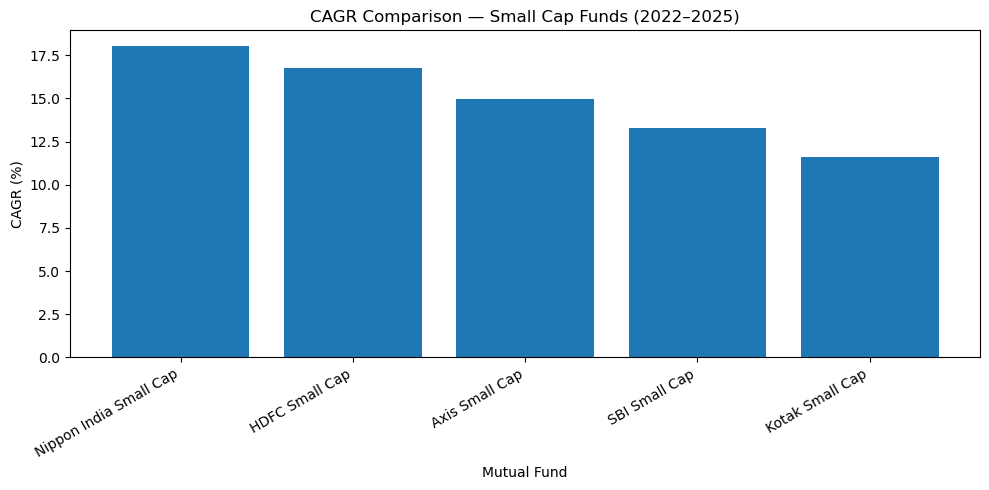

In [14]:
plot_data = small_cap_results.sort_values("CAGR", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["CAGR"] * 100)
plt.title("CAGR Comparison — Small Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("CAGR (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_cagr.png", dpi=300, bbox_inches="tight")
plt.show()


### Annualized volatility

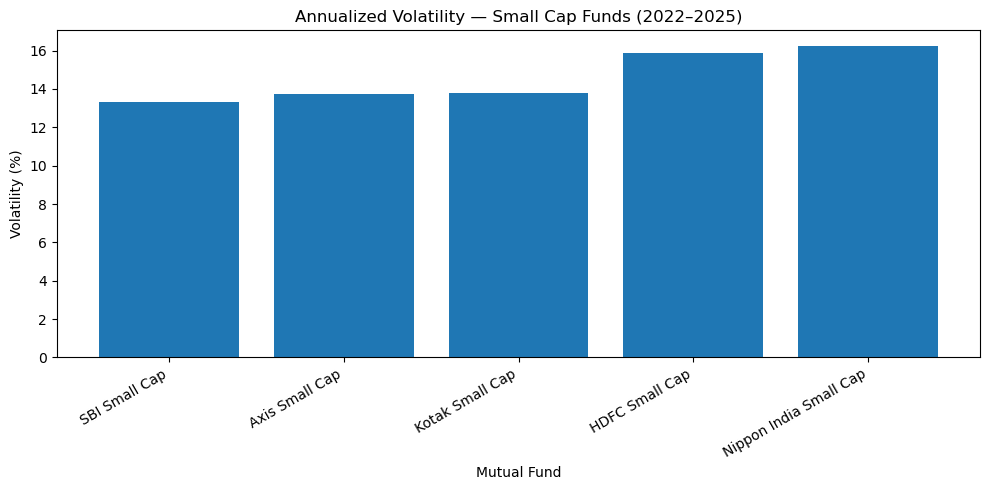

In [15]:
plot_data = small_cap_results.sort_values("Volatility", ascending=True)
plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["Volatility"] * 100)
plt.title("Annualized Volatility — Small Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Volatility (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_volatility.png", dpi=300, bbox_inches="tight")
plt.show()


### Maximum drawdown

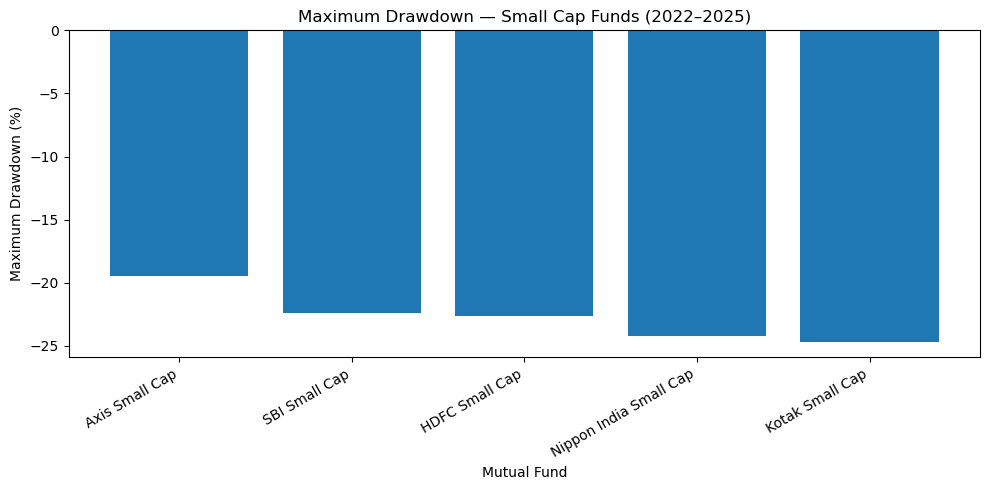

In [16]:
plot_data = small_cap_results.sort_values("Maximum Drawdown", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["Maximum Drawdown"] * 100)
plt.title("Maximum Drawdown — Small Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Maximum Drawdown (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_max_drawdown.png", dpi=300, bbox_inches="tight")
plt.show()


### Sharpe ratio

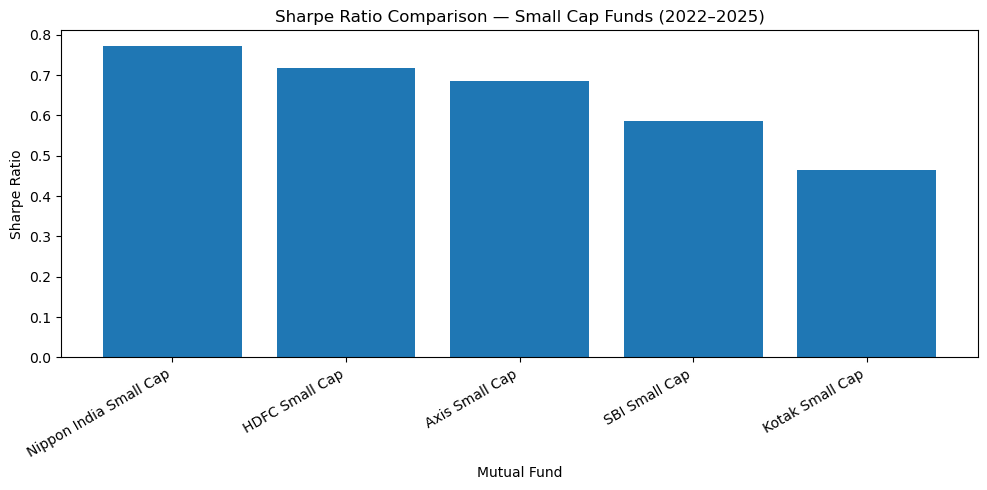

In [17]:
plot_data = small_cap_results.sort_values("Sharpe Ratio", ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["Sharpe Ratio"])
plt.title("Sharpe Ratio Comparison — Small Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Sharpe Ratio")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()


### Risk vs. return

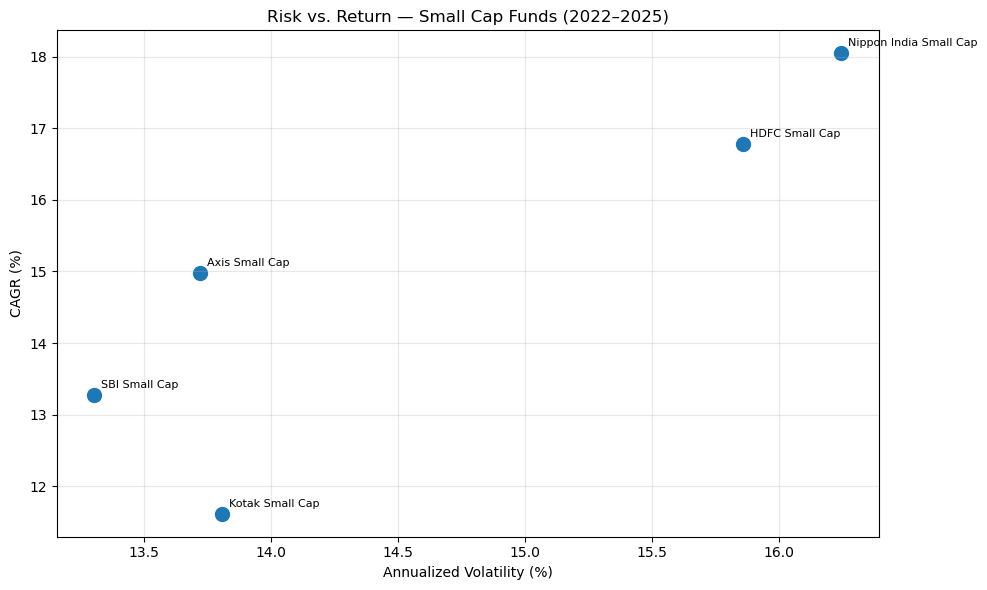

In [18]:
plt.figure(figsize=(10, 6))
plt.scatter(small_cap_results["Volatility"] * 100, small_cap_results["CAGR"] * 100, s=100)
for _, row in small_cap_results.iterrows():
    plt.annotate(row["Fund"], (row["Volatility"] * 100, row["CAGR"] * 100), xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.title("Risk vs. Return — Small Cap Funds (2022–2025)")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("CAGR (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_risk_return.png", dpi=300, bbox_inches="tight")
plt.show()


### Performance metrics heatmap

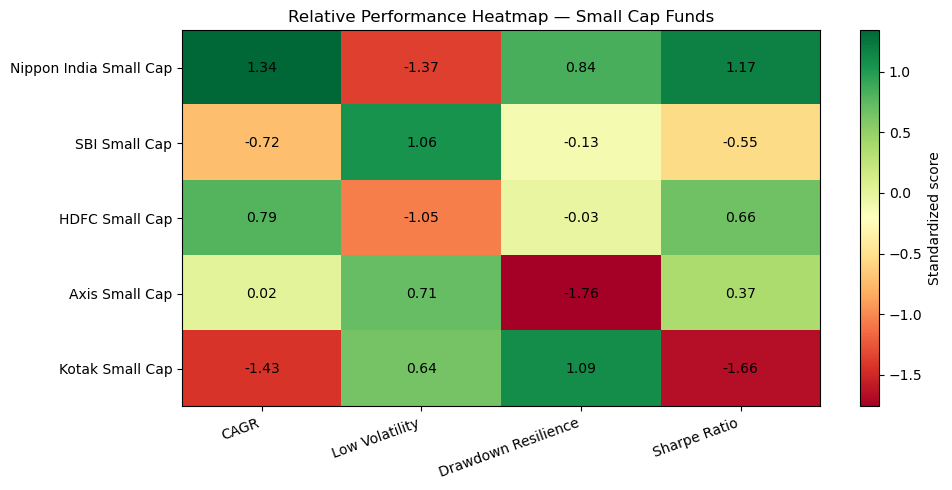

In [19]:
metrics = small_cap_results.set_index("Fund")[["CAGR", "Volatility", "Maximum Drawdown", "Sharpe Ratio"]].copy()
metrics["Maximum Drawdown"] = -metrics["Maximum Drawdown"]
metrics["Volatility"] = -metrics["Volatility"]
scores = (metrics - metrics.mean()) / metrics.std(ddof=0)
plt.figure(figsize=(10, 5))
image = plt.imshow(scores, aspect="auto", cmap="RdYlGn")
plt.xticks(range(len(scores.columns)), ["CAGR", "Low Volatility", "Drawdown Resilience", "Sharpe Ratio"], rotation=20, ha="right")
plt.yticks(range(len(scores.index)), scores.index)
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(j, i, f"{scores.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(image, label="Standardized score")
plt.title("Relative Performance Heatmap — Small Cap Funds")
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


### Radar chart

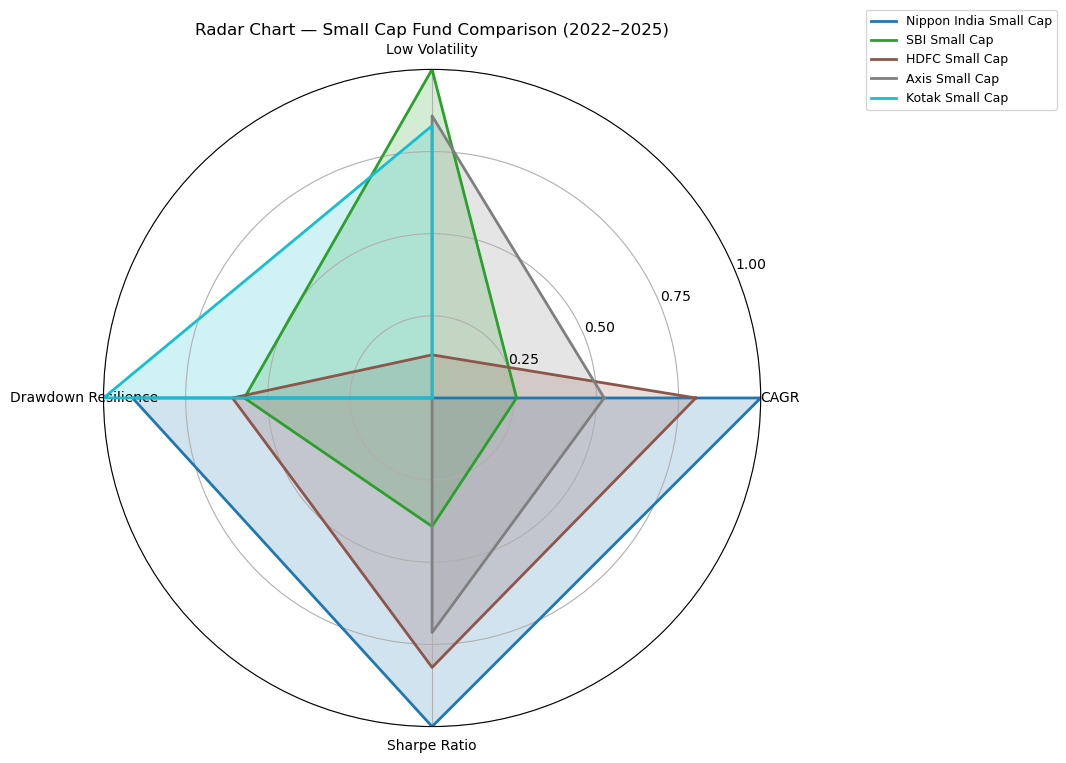

In [20]:
import numpy as np

metrics = small_cap_results.set_index("Fund")[["CAGR", "Volatility", "Maximum Drawdown", "Sharpe Ratio"]].copy()
metrics["Volatility"] = -metrics["Volatility"]
metrics["Maximum Drawdown"] = -metrics["Maximum Drawdown"]
normalized = ((metrics - metrics.min()) / (metrics.max() - metrics.min())).fillna(0)
categories = ["CAGR", "Low Volatility", "Drawdown Resilience", "Sharpe Ratio"]
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(10, 9), subplot_kw={"polar": True})
colors = plt.cm.tab10(np.linspace(0, 1, len(normalized)))
for (fund_name, row), color in zip(normalized.iterrows(), colors):
    values = row.tolist() + row.tolist()[:1]
    ax.plot(angles, values, linewidth=2, color=color, label=fund_name)
    ax.fill(angles, values, color=color, alpha=0.20)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"])
ax.set_title("Radar Chart — Small Cap Fund Comparison (2022–2025)", pad=25)
ax.legend(loc="upper left", bbox_to_anchor=(1.15, 1.10), fontsize=9)
plt.tight_layout()
plt.savefig(charts_dir / "small_cap_radar.png", dpi=300, bbox_inches="tight")
plt.show()
